# **Basic metrics**

This notebook illustrates the following concepts:

1. Degree centrality  
2. Closeness centrality  
3. Betweenness centrality  
4. Eigenvector centrality  
5. PageRank  
6. Clustering coefficient  
7. Average path length, density, and diameter  
8. Modularity and community detection  

### Notes

NetworkX's Karate Club graph contains an edge attribute called `weight`. This notebook uses `weight=None` whenever NetworkX might otherwise use edge weights.

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display
from networkx.algorithms.community.quality import modularity

TOP_K = 5
SHOW_ALL_METRIC_PLOTS = False

print("NetworkX version:", nx.__version__)

NetworkX version: 3.2.1


## 0. Load the dataset

Zachary's Karate Club is a classic social-network dataset. Nodes represent club members and edges represent social ties.

In [3]:
G = nx.karate_club_graph()

n = G.number_of_nodes()
m = G.number_of_edges()

club = nx.get_node_attributes(G, "club")
club_names = sorted(set(club.values()))
club_code = {node: club_names.index(club[node]) for node in G.nodes()}

# Fixed layout so that all visual comparisons use exactly the same geometry.
pos = nx.spring_layout(G, seed=42, weight=None)

print("Zachary's Karate Club")
print("======================")
print(f"Nodes: {n}")
print(f"Edges: {m}")
print(f"Connected: {nx.is_connected(G)}")
print(f"Observed club labels: {club_names}")

Zachary's Karate Club
Nodes: 34
Edges: 78
Connected: True
Observed club labels: ['Mr. Hi', 'Officer']


### Utilities

In [4]:
def top_k(metric, k=TOP_K):
    """Return the k highest-scoring nodes for a node -> value dictionary."""
    return sorted(metric.items(), key=lambda item: item[1], reverse=True)[:k]


def draw_metric(G, pos, metric, title, club_code):
    """Node size = metric value; node color = observed club."""
    values = [metric[node] for node in G.nodes()]
    max_value = max(values) if values else 1.0
    sizes = [250 + 2200 * (metric[node] / max_value) for node in G.nodes()]

    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.25)
    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=sizes,
        node_color=[club_code[node] for node in G.nodes()],
        cmap=plt.get_cmap("tab10"),
        edgecolors="black",
        linewidths=0.6,
        alpha=0.9,
    )
    nx.draw_networkx_labels(G, pos, font_size=8)
    plt.title(title + "\nnode size = measure; node color = observed club")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def draw_partition(G, pos, partition, title):
    """Draw a community partition."""
    node_to_community = {
        node: community_id
        for community_id, community in enumerate(partition)
        for node in community
    }

    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.25)
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=[node_to_community[node] for node in G.nodes()],
        cmap=plt.get_cmap("tab10"),
        node_size=500,
        edgecolors="black",
        linewidths=0.6,
    )
    nx.draw_networkx_labels(G, pos, font_size=8)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Degree centrality

**Question:** Who has the most direct connections?

For an undirected graph, raw degree is the number of neighbors. NetworkX reports normalized degree centrality as

$C_D(v)=\frac{k_v}{n-1}$ .

This makes degree centrality comparable across networks of different sizes.

Node 33: degree = 17, normalized degree centrality = 0.515 = 17/33
Top nodes: [(33, 0.5151515151515151), (0, 0.48484848484848486), (32, 0.36363636363636365), (2, 0.30303030303030304), (1, 0.2727272727272727)]


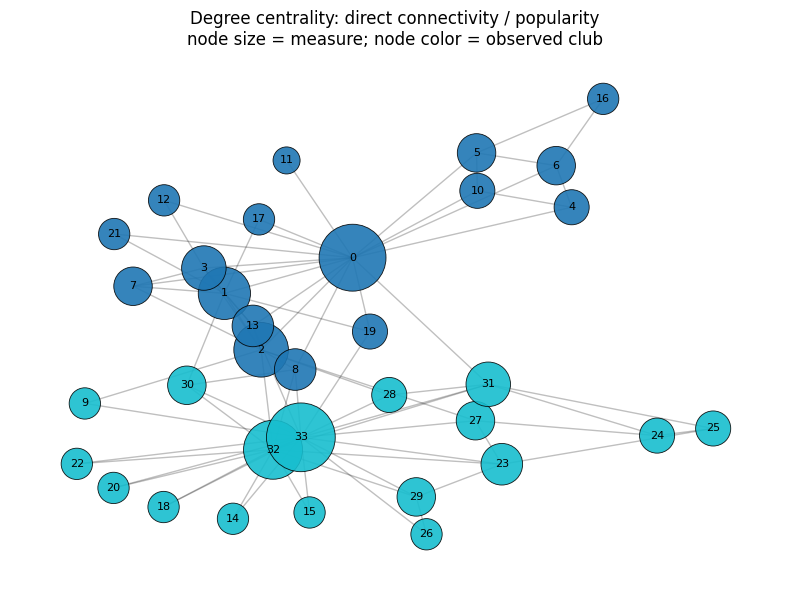

In [5]:
degree = dict(G.degree())
degree_centrality = nx.degree_centrality(G)

degree_winner = max(degree, key=degree.get)

print(
    f"Node {degree_winner}: degree = {degree[degree_winner]}, "
    f"normalized degree centrality = {degree_centrality[degree_winner]:.3f} "
    f"= {degree[degree_winner]}/{n - 1}"
)
print("Top nodes:", top_k(degree_centrality))

draw_metric(
    G,
    pos,
    degree_centrality,
    "Degree centrality: direct connectivity / popularity",
    club_code,
)

## 2. Closeness centrality

**Question:** Who can reach the rest of the network in the fewest steps?

For this connected graph, NetworkX uses the reciprocal of the average shortest-path distance:

$C_C(v)=\frac{n-1}{\sum_u d(u,v)}$.

A node with high closeness is, on average, only a small number of hops away from everyone else.

In [6]:
closeness = nx.closeness_centrality(G)

closeness_winner = max(closeness, key=closeness.get)
distances = nx.single_source_shortest_path_length(G, closeness_winner)
mean_distance = sum(distances.values()) / (n - 1)

print(
    f"Node {closeness_winner} has the highest closeness: "
    f"{closeness[closeness_winner]:.3f}"
)
print(f"Mean shortest-path distance from that node: {mean_distance:.3f} steps")
print("Top nodes:", top_k(closeness))

if SHOW_ALL_METRIC_PLOTS:
    draw_metric(
        G,
        pos,
        closeness,
        "Closeness centrality: short average distance to the network",
        club_code,
    )

Node 0 has the highest closeness: 0.569
Mean shortest-path distance from that node: 1.758 steps
Top nodes: [(0, 0.5689655172413793), (2, 0.559322033898305), (33, 0.55), (31, 0.5409836065573771), (8, 0.515625)]


## 3. Betweenness centrality

**Question:** Who acts as a broker or bridge?

Betweenness measures how often a node lies on shortest paths between other pairs of nodes.

*Remove the highest-betweenness node and examine what happens to connectivity.*


Highest-betweenness node: 0 (0.438)
Top nodes: [(0, 0.43763528138528146), (33, 0.30407497594997596), (32, 0.145247113997114), (2, 0.14365680615680618), (31, 0.13827561327561325)]
Connected components: before removal = 1, after removal = 3
Component sizes after removal: [27, 5, 1]


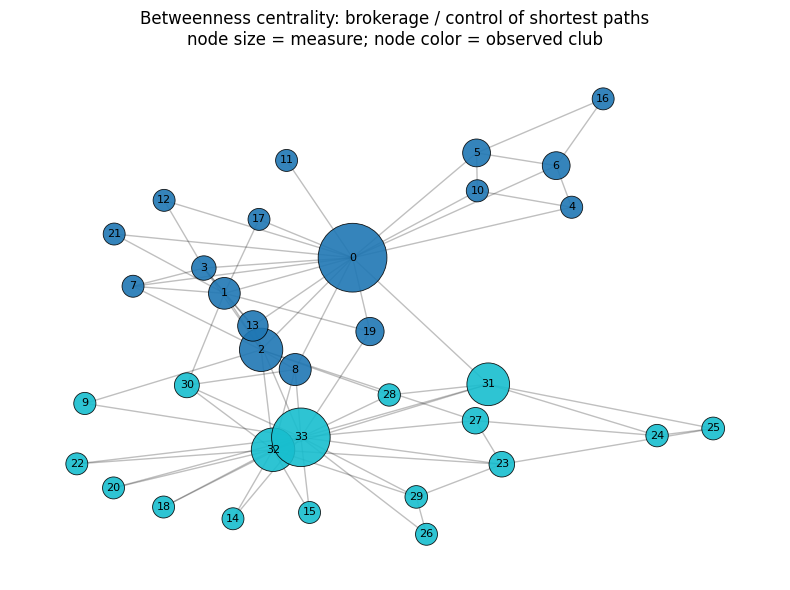

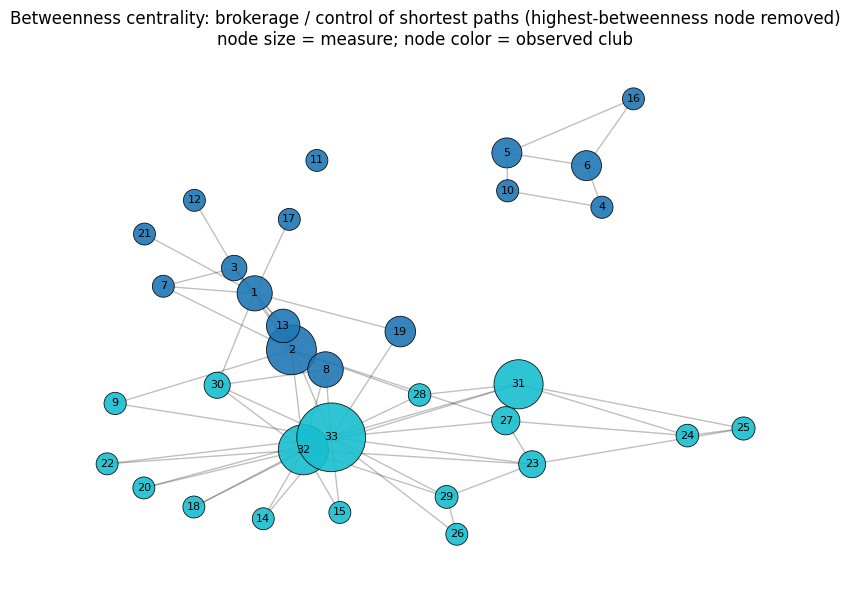

In [7]:
betweenness = nx.betweenness_centrality(G, weight=None, normalized=True)
broker = max(betweenness, key=betweenness.get)

H = G.copy()
H.remove_node(broker)

print(f"Highest-betweenness node: {broker} ({betweenness[broker]:.3f})")
print("Top nodes:", top_k(betweenness))
print(
    "Connected components: "
    f"before removal = {nx.number_connected_components(G)}, "
    f"after removal = {nx.number_connected_components(H)}"
)
print(
    "Component sizes after removal:",
    sorted((len(c) for c in nx.connected_components(H)), reverse=True),
)

draw_metric(
    G,
    pos,
    betweenness,
    "Betweenness centrality: brokerage / control of shortest paths",
    club_code,
)

draw_metric(
    H,
    pos,
    betweenness,
    "Betweenness centrality: brokerage / control of shortest paths (highest-betweenness node removed)",
    club_code,
)

## 4. Eigenvector centrality

**Question:** Who is connected to other important people?

Eigenvector centrality gives a node a high score when it is connected to neighbors that themselves have high scores. It therefore emphasizes the *quality* as well as the quantity of connections.

Top nodes: [(33, 0.373371213013235), (0, 0.3554834941851943), (2, 0.3171893899684447), (32, 0.30865104773369595), (1, 0.2659538704545025)]


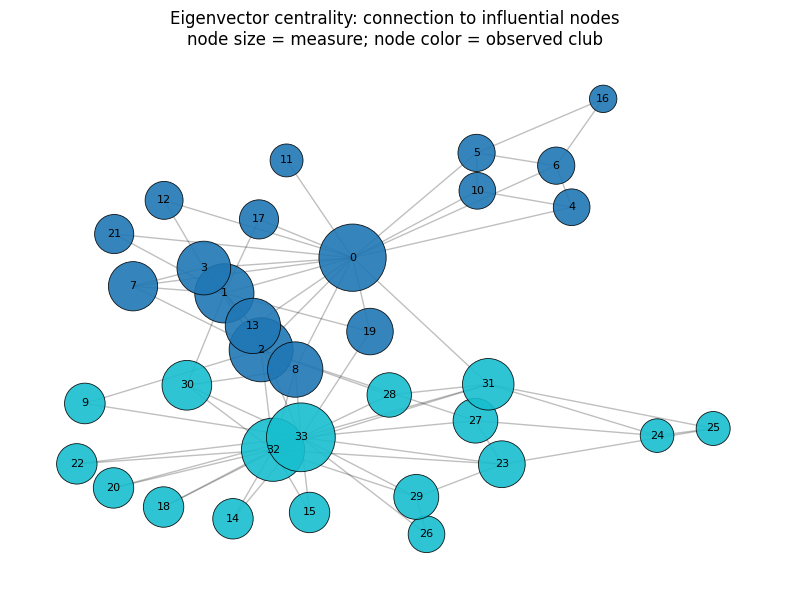

In [8]:
eigenvector = nx.eigenvector_centrality(G, weight=None, max_iter=1000)

print("Top nodes:", top_k(eigenvector))

draw_metric(
    G,
    pos,
    eigenvector,
    "Eigenvector centrality: connection to influential nodes",
    club_code,
)

## 5. PageRank

PageRank can be interpreted as the long-run probability that a random walker occupies a node, with occasional random jumps.

Here the Karate graph is *undirected*, so every friendship can effectively be traversed in both directions. This demonstrates the random-walk ranking idea, but not directed in-degree/out-degree asymmetry.

In [9]:
pagerank = nx.pagerank(G, alpha=0.85, weight=None)

print("Top nodes:", top_k(pagerank))

if SHOW_ALL_METRIC_PLOTS:
    draw_metric(
        G,
        pos,
        pagerank,
        "PageRank on the undirected Karate graph",
        club_code,
    )

ModuleNotFoundError: No module named 'scipy'

## 6. Clustering coefficient

The *local clustering coefficient* measures how strongly a node's neighbors are connected to one another.

The *average clustering coefficient* summarizes this tendency over the whole network.

This helps distinguish nodes embedded in tightly knit circles from nodes acting as bridges between groups.

In [ ]:
local_clustering = nx.clustering(G, weight=None)
average_clustering = nx.average_clustering(G, weight=None)

print(f"Average clustering coefficient: {average_clustering:.3f}")
print("Highest local clustering:", top_k(local_clustering))

high_degree_nodes = [
    node
    for node, _ in sorted(degree.items(), key=lambda item: item[1], reverse=True)[:2]
]

for node in high_degree_nodes:
    print(
        f"Node {node}: degree = {degree[node]}, "
        f"local clustering = {local_clustering[node]:.3f}"
    )

if SHOW_ALL_METRIC_PLOTS:
    draw_metric(
        G,
        pos,
        local_clustering,
        "Local clustering coefficient: how connected a node's neighbors are",
        club_code,
    )

Average clustering coefficient: 0.571
Highest local clustering: [(7, 1.0), (12, 1.0), (14, 1.0), (15, 1.0), (16, 1.0)]
Node 33: degree = 17, local clustering = 0.110
Node 0: degree = 16, local clustering = 0.150


## 7. Network-level measures

Now move from node-level importance to properties of the *whole network*:

- *Average path length:* typical shortest-path distance between two nodes
- *Density:* fraction of possible edges that actually exist
- *Diameter:* the longest among all shortest paths

In [ ]:
average_path_length = nx.average_shortest_path_length(G, weight=None)
density = nx.density(G)

# NetworkX versions differ slightly in the diameter signature.
try:
    diameter = nx.diameter(G, weight=None)
except TypeError:
    diameter = nx.diameter(G)

possible_edges = n * (n - 1) // 2

diameter_path = None
for source in G.nodes():
    for target in G.nodes():
        if source < target:
            path = nx.shortest_path(G, source, target)
            if len(path) - 1 == diameter:
                diameter_path = path
                break
    if diameter_path is not None:
        break

print(f"Average path length: {average_path_length:.3f}")
print(f"Density: {density:.3f} = {m}/{possible_edges} possible undirected edges")
print(f"Diameter: {diameter}")
print(f"Example diameter path: {diameter_path}")

Average path length: 2.408
Density: 0.139 = 78/561 possible undirected edges
Diameter: 5
Example diameter path: [14, 32, 2, 0, 5, 16]


## 8. Modularity and community detection

Modularity measures how strongly a network can be partitioned into groups with many within-group edges and relatively few between-group edges.

We use *Louvain* when available because it is the example community-detection method mentioned in the lab. We then compare the detected partition with the *observed historical split* of the Karate Club.

Note that partition maximizing modularity does not have to reproduce the real historical split exactly.

In [ ]:
if hasattr(nx.community, "louvain_communities"):
    detected = list(nx.community.louvain_communities(G, seed=42, weight=None))
    algorithm = "Louvain"
else:
    detected = list(nx.community.greedy_modularity_communities(G, weight=None))
    algorithm = "greedy modularity (fallback)"

detected_modularity = modularity(G, detected, weight=None)

observed_partition = [
    {node for node in G.nodes() if club[node] == club_name}
    for club_name in club_names
]
observed_modularity = modularity(G, observed_partition, weight=None)

print(f"Detected with {algorithm}: {len(detected)} communities")
print("Detected community sizes:", sorted((len(c) for c in detected), reverse=True))
print(f"Detected-partition modularity Q = {detected_modularity:.3f}")
print(
    f"Observed historical split: {len(observed_partition)} groups, "
    f"sizes {[len(c) for c in observed_partition]}, "
    f"Q = {observed_modularity:.3f}"
)

Detected with Louvain: 3 communities
Detected community sizes: [17, 13, 4]
Detected-partition modularity Q = 0.385
Observed historical split: 2 groups, sizes [17, 17], Q = 0.358


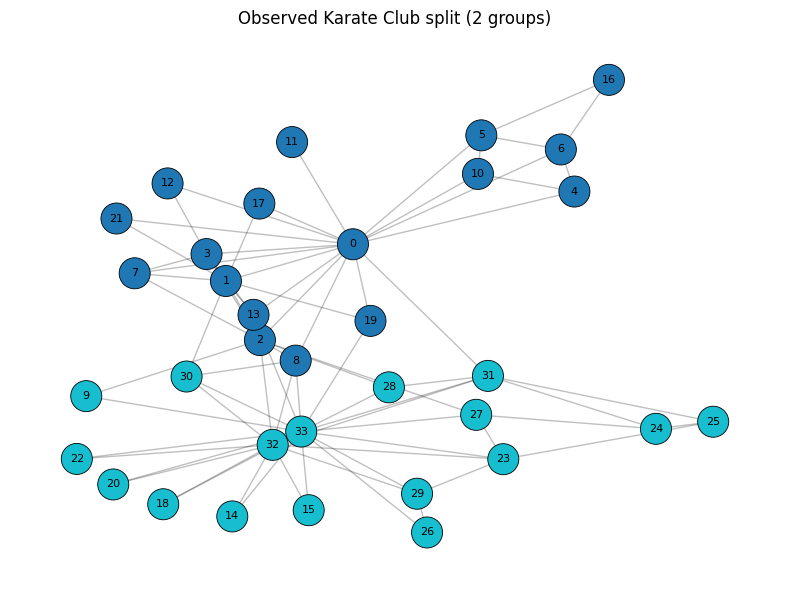

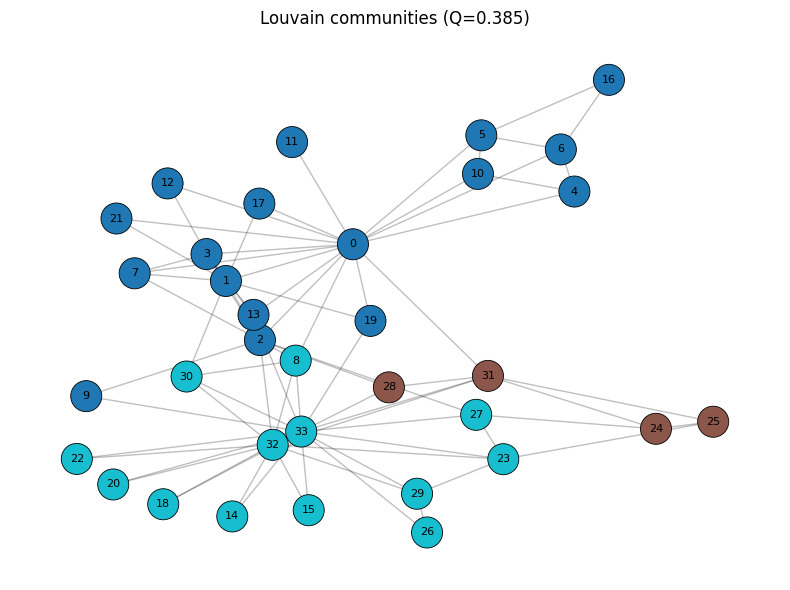

In [ ]:
draw_partition(
    G,
    pos,
    observed_partition,
    "Observed Karate Club split (2 groups)",
)

draw_partition(
    G,
    pos,
    detected,
    f"{algorithm} communities (Q={detected_modularity:.3f})",
)

## 9. Compare all node-level measures

Different centrality measures answer different questions, so the most important node can change depending on the definition of "important".

In [ ]:
results = pd.DataFrame(
    {
        "node": list(G.nodes()),
        "club": [club[node] for node in G.nodes()],
        "degree": [degree[node] for node in G.nodes()],
        "degree_centrality": [degree_centrality[node] for node in G.nodes()],
        "closeness": [closeness[node] for node in G.nodes()],
        "betweenness": [betweenness[node] for node in G.nodes()],
        "eigenvector": [eigenvector[node] for node in G.nodes()],
        "pagerank": [pagerank[node] for node in G.nodes()],
        "local_clustering": [local_clustering[node] for node in G.nodes()],
    }
)

display(
    results.sort_values("betweenness", ascending=False)
    .head(10)
    .round(3)
)

,node,club,degree,degree_centrality,closeness,betweenness,eigenvector,pagerank,local_clustering
0,0,Mr. Hi,16,0.485,0.569,0.438,0.355,0.097,0.150
33,33,Officer,17,0.515,0.550,0.304,0.373,0.101,0.110
32,32,Officer,12,0.364,0.516,0.145,0.309,0.072,0.197
2,2,Mr. Hi,10,0.303,0.559,0.144,0.317,0.057,0.244
31,31,Officer,6,0.182,0.541,0.138,0.191,0.037,0.200
8,8,Mr. Hi,5,0.152,0.516,0.056,0.227,0.030,0.500
1,1,Mr. Hi,9,0.273,0.485,0.054,0.266,0.053,0.333
13,13,Mr. Hi,5,0.152,0.516,0.046,0.226,0.030,0.600
19,19,Mr. Hi,3,0.091,0.500,0.032,0.148,0.020,0.333
5,5,Mr. Hi,4,0.121,0.384,0.030,0.079,0.029,0.500


## 10. Discussions

1. Do degree, closeness, betweenness, eigenvector centrality, and PageRank identify the same "important" nodes? Why or why not?
2. Why can a node have many neighbors but relatively low local clustering?
3. What happens structurally when the highest-betweenness node is removed?
4. What does the low density tell us about this social network?

### Note

Set

```python
SHOW_ALL_METRIC_PLOTS = True
```

near the top of the notebook and rerun all cells to also visualize closeness, PageRank, and local clustering.